
# RQ21 — Joint R×S trajectories and asymmetric strictness allocation

## Scientific question

**What happens when redundancy control (`R`) and homology separation (`S`) become stricter jointly, and is a given amount of nominal joint strictness equally difficult when it is allocated primarily to R versus primarily to S?**

RQ21 is the dedicated mixed-trajectory analysis required by the roadmap. It uses the already completed supervised `R×S` landscapes and does **not** train models, regenerate predictions, or repeat bootstrap uncertainty.

The canonical diagonal trajectory is:

```text
R90/S90
→ R70/S70
→ R50/S50
→ R30/S30
```

This trajectory is used only to quantify **joint strictness**. It is never interpreted as an isolated R effect or isolated S effect because both factors change simultaneously.

RQ21 additionally compares cells with comparable nominal joint strictness but different allocation between R and S, e.g.:

```text
R50/S90  vs  R90/S50
```

to test whether equal nominal joint strictness implies equal predictive difficulty.



## Analysis contract

### 1. Joint strictness index

The ordered identity thresholds are mapped to ordinal strictness:

```text
90 → 0
70 → 1
50 → 2
30 → 3
```

For each cell,

\[
J = j_R + j_S
\]

ranges from `0` (`R90/S90`) to `6` (`R30/S30`).

`J` is used only to group cells with **comparable ordinal strictness**. It is not assumed to be a biological distance scale.

### 2. Diagonal retention

For each `task × representation × algorithm` surface, RQ21 records:

- MCC at all four diagonal cells;
- \(\Delta MCC\) relative to `R90/S90`;
- performance retention \(M(R,S)/M(90,90)\) when the baseline MCC is positive and non-zero;
- the three consecutive joint-step deltas.

Because ratio-type retention can become unstable near zero, **baseline-relative ΔMCC remains the primary quantity**.

### 3. Asymmetric allocation contrasts

For matched nominal strictness, define:

\[
A = M(\text{R-stricter, S-looser})
-
M(\text{R-looser, S-stricter}).
\]

Therefore:

- `A < 0`: allocating strictness to **R** is more damaging;
- `A > 0`: allocating strictness to **S** is more damaging;
- `A ≈ 0`: the two allocations behave similarly.

The six canonical swapped contrasts are:

```text
R70/S90 vs R90/S70
R50/S90 vs R90/S50
R30/S90 vs R90/S30
R50/S70 vs R70/S50
R30/S70 vs R70/S30
R30/S50 vs R50/S30
```

### 4. Within-J spread

At each joint strictness level `J`, the spread among all cells with that same `J` quantifies whether `J` alone is sufficient to characterize difficulty.

A large spread means:

> **the distribution of strictness between R and S matters, not only its nominal total.**

### 5. Additive expectation along the diagonal

For contextual interpretation only, RQ21 compares each diagonal cell against the additive expectation derived from the two corresponding single-axis moves from `R90/S90`:

\[
M_{\mathrm{add}}(R,S)
=
M(R,90)+M(90,S)-M(90,90).
\]

Then:

\[
E_{\mathrm{joint}}
=
M(R,S)-M_{\mathrm{add}}(R,S).
\]

Positive values indicate **attenuation / partial compensation** of the two isolated penalties. RQ4 remains the canonical full factorial interaction analysis; RQ21 uses this only to interpret the mixed diagonal path.


In [1]:

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 300)

LEVELS = [90, 70, 50, 30]
STRICTNESS_MAP = {90: 0, 70: 1, 50: 2, 30: 3}
DIAGONAL = [(90, 90), (70, 70), (50, 50), (30, 30)]
PRIMARY_METRIC = "mcc"
ASYM_TOL = 0.005

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

ALG_ORDER = ["KNN", "LR", "MLP", "RF", "XGB"]

TASK_LABEL = {
    "global_easy": "Global easy",
    "global_hard": "Global hard",
    "global_mixed": "Global mixed",
    "subtype_endolysin": "Endolysin",
    "subtype_depolymerase": "Depolymerase",
    "subtype_val": "VAL",
    "multiclass_clean": "Multiclass",
}

REP_LABEL = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        rq6 = candidate / "results/analysis_supervised/notebook_cache/rq6_surface_geometry/rq6_surface_cells.tsv"
        master = candidate / "results/analysis_supervised/stage12a/supervised_master_results.tsv"
        if rq6.is_file() and master.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate project root with completed RQ6 cache and Stage12A master results."
    )


ROOT = find_project_root()
RQ6_DIR = ROOT / "results/analysis_supervised/notebook_cache/rq6_surface_geometry"
RQ21_OUT = ROOT / "results/analysis_supervised/notebook_cache/rq21_joint_RxS_trajectories"
FIG_DIR = RQ21_OUT / "figures"
RQ21_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ21_OUT:", RQ21_OUT)
print("No model training, prediction regeneration, common-test recalculation, or bootstrap is performed.")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ21_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq21_joint_RxS_trajectories
No model training, prediction regeneration, common-test recalculation, or bootstrap is performed.


## 1. Load and validate canonical RQ6 surface cells

In [2]:

surface_cells = pd.read_csv(
    RQ6_DIR / "rq6_surface_cells.tsv",
    sep="\t",
    low_memory=False,
)

required = {
    "task", "representation", "algorithm", "R", "S",
    PRIMARY_METRIC, "delta_from_R90S90",
}
missing = required - set(surface_cells.columns)
if missing:
    raise KeyError(f"RQ6 surface cells missing required columns: {sorted(missing)}")

for c in ["R", "S", PRIMARY_METRIC, "delta_from_R90S90"]:
    surface_cells[c] = pd.to_numeric(surface_cells[c], errors="raise")

surface_cells["R"] = surface_cells["R"].astype(int)
surface_cells["S"] = surface_cells["S"].astype(int)

group_cols = ["task", "representation", "algorithm"]

assert len(surface_cells) == 2240
assert surface_cells.groupby(group_cols).size().eq(16).all()
assert len(surface_cells.groupby(group_cols)) == 140
assert set(surface_cells["R"].unique()) == set(LEVELS)
assert set(surface_cells["S"].unique()) == set(LEVELS)
assert not surface_cells.duplicated(group_cols + ["R", "S"]).any()

surface_cells["R_strictness"] = surface_cells["R"].map(STRICTNESS_MAP)
surface_cells["S_strictness"] = surface_cells["S"].map(STRICTNESS_MAP)
surface_cells["joint_strictness"] = (
    surface_cells["R_strictness"] + surface_cells["S_strictness"]
)
surface_cells["strictness_imbalance"] = (
    surface_cells["R_strictness"] - surface_cells["S_strictness"]
)

print("Rows:", len(surface_cells))
print("Complete surfaces:", surface_cells.groupby(group_cols).ngroups)
print("Joint strictness levels:", sorted(surface_cells["joint_strictness"].unique()))
print("RQ6_INPUT_PREFLIGHT_OK")


Rows: 2240
Complete surfaces: 140
Joint strictness levels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
RQ6_INPUT_PREFLIGHT_OK


## 2. Reconstruct the four-point joint diagonal

In [3]:

diag = surface_cells[
    surface_cells.apply(lambda r: (int(r["R"]), int(r["S"])) in DIAGONAL, axis=1)
].copy()

diag["diagonal_order"] = [
    STRICTNESS_MAP[int(r)] for r in diag["R"]
]
diag["diagonal_cell"] = (
    "R" + diag["R"].astype(str) + "/S" + diag["S"].astype(str)
)

baseline = (
    surface_cells[
        surface_cells["R"].eq(90) & surface_cells["S"].eq(90)
    ][group_cols + [PRIMARY_METRIC]]
    .rename(columns={PRIMARY_METRIC: "baseline_mcc_R90S90"})
)

diag = diag.merge(
    baseline,
    on=group_cols,
    how="left",
    validate="many_to_one",
)

diag["joint_delta_from_baseline"] = (
    diag[PRIMARY_METRIC] - diag["baseline_mcc_R90S90"]
)

diag["retention_fraction"] = np.where(
    diag["baseline_mcc_R90S90"] > 1e-12,
    diag[PRIMARY_METRIC] / diag["baseline_mcc_R90S90"],
    np.nan,
)

diag = diag.sort_values(group_cols + ["diagonal_order"]).reset_index(drop=True)

assert len(diag) == 140 * 4
assert diag.groupby(group_cols).size().eq(4).all()
assert diag.loc[diag["diagonal_order"].eq(0), "joint_delta_from_baseline"].abs().max() < 1e-12

display(
    diag[
        group_cols
        + [
            "diagonal_cell", PRIMARY_METRIC,
            "joint_delta_from_baseline", "retention_fraction"
        ]
    ].head(20)
)


,task,representation,algorithm,diagonal_cell,mcc,joint_delta_from_baseline,retention_fraction
0,global_easy,esm2_t30_150m,KNN,R90/S90,0.962580,0.000000,1.000000
1,global_easy,esm2_t30_150m,KNN,R70/S70,0.950576,-0.012004,0.987530
2,global_easy,esm2_t30_150m,KNN,R50/S50,0.935653,-0.026927,0.972027
3,global_easy,esm2_t30_150m,KNN,R30/S30,0.887662,-0.074918,0.922169
4,global_easy,esm2_t30_150m,LR,R90/S90,0.929346,0.000000,1.000000
5,global_easy,esm2_t30_150m,LR,R70/S70,0.910743,-0.018604,0.979982
6,global_easy,esm2_t30_150m,LR,R50/S50,0.887692,-0.041655,0.955179
7,global_easy,esm2_t30_150m,LR,R30/S30,0.840543,-0.088803,0.904445
8,global_easy,esm2_t30_150m,MLP,R90/S90,0.960914,0.000000,1.000000
9,global_easy,esm2_t30_150m,MLP,R70/S70,0.945210,-0.015704,0.983657


## 3. Consecutive changes along the joint diagonal

In [4]:

joint_step_rows = []

for keys, grp in diag.groupby(group_cols, sort=False):
    task, rep, alg = keys
    g = grp.sort_values("diagonal_order")
    rows = list(g.to_dict("records"))

    for a, b in zip(rows[:-1], rows[1:]):
        joint_step_rows.append({
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "from_cell": a["diagonal_cell"],
            "to_cell": b["diagonal_cell"],
            "from_joint_strictness": int(a["joint_strictness"]),
            "to_joint_strictness": int(b["joint_strictness"]),
            "value_from": float(a[PRIMARY_METRIC]),
            "value_to": float(b[PRIMARY_METRIC]),
            "delta": float(b[PRIMARY_METRIC] - a[PRIMARY_METRIC]),
            "abs_delta": float(abs(b[PRIMARY_METRIC] - a[PRIMARY_METRIC])),
        })

joint_steps = pd.DataFrame(joint_step_rows)

assert len(joint_steps) == 140 * 3

joint_step_summary = (
    joint_steps.groupby(["from_cell", "to_cell"], as_index=False)
    .agg(
        n=("delta", "size"),
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        q25=("delta", lambda x: x.quantile(0.25)),
        q75=("delta", lambda x: x.quantile(0.75)),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
        fraction_positive=("delta", lambda x: (x > 0).mean()),
    )
)

display(joint_step_summary)


,from_cell,to_cell,n,mean_delta,median_delta,q25,q75,median_abs_delta,fraction_negative,fraction_positive
0,R50/S50,R30/S30,140,-0.015205,-0.021579,-0.048220,0.004177,0.038471,0.664286,0.307143
1,R70/S70,R50/S50,140,-0.066683,-0.038054,-0.066728,-0.014890,0.038369,0.914286,0.064286
2,R90/S90,R70/S70,140,-0.033881,-0.021233,-0.049877,-0.002040,0.024464,0.778571,0.221429


## 4. Diagonal retention by task, representation, and learner

In [5]:

diag_task = (
    diag.groupby(["task", "diagonal_order", "diagonal_cell"], as_index=False)
    .agg(
        median_mcc=(PRIMARY_METRIC, "median"),
        median_delta=("joint_delta_from_baseline", "median"),
        median_retention=("retention_fraction", "median"),
        q25_delta=("joint_delta_from_baseline", lambda x: x.quantile(0.25)),
        q75_delta=("joint_delta_from_baseline", lambda x: x.quantile(0.75)),
    )
)

diag_rep = (
    diag.groupby(["representation", "diagonal_order", "diagonal_cell"], as_index=False)
    .agg(
        median_mcc=(PRIMARY_METRIC, "median"),
        median_delta=("joint_delta_from_baseline", "median"),
        median_retention=("retention_fraction", "median"),
    )
)

diag_alg = (
    diag.groupby(["algorithm", "diagonal_order", "diagonal_cell"], as_index=False)
    .agg(
        median_mcc=(PRIMARY_METRIC, "median"),
        median_delta=("joint_delta_from_baseline", "median"),
        median_retention=("retention_fraction", "median"),
    )
)

print("Task-level diagonal retention")
display(diag_task)

print("Representation-level diagonal retention")
display(diag_rep)


Task-level diagonal retention


,task,diagonal_order,diagonal_cell,median_mcc,median_delta,median_retention,q25_delta,q75_delta
0,global_easy,0,R90/S90,0.774564,0.000000,1.000000,0.000000,0.000000
1,global_easy,1,R70/S70,0.757290,-0.026728,0.961273,-0.078449,-0.017304
2,global_easy,2,R50/S50,0.695659,-0.075309,0.913303,-0.139020,-0.049364
3,global_easy,3,R30/S30,0.664537,-0.131290,0.844879,-0.191727,-0.087508
4,global_hard,0,R90/S90,0.939674,0.000000,1.000000,0.000000,0.000000
5,global_hard,1,R70/S70,0.900973,-0.025580,0.973306,-0.043765,-0.017089
6,global_hard,2,R50/S50,0.892193,-0.038816,0.957691,-0.068409,-0.023593
7,global_hard,3,R30/S30,0.873673,-0.063979,0.933253,-0.079084,-0.054516
8,global_mixed,0,R90/S90,0.783495,0.000000,1.000000,0.000000,0.000000
9,global_mixed,1,R70/S70,0.735053,-0.032725,0.949976,-0.067338,-0.013095


Representation-level diagonal retention


,representation,diagonal_order,diagonal_cell,median_mcc,median_delta,median_retention
0,esm2_t30_150m,0,R90/S90,0.929346,0.000000,1.000000
1,esm2_t30_150m,1,R70/S70,0.932059,-0.008477,0.991141
2,esm2_t30_150m,2,R50/S50,0.888367,-0.035923,0.962457
3,esm2_t30_150m,3,R30/S30,0.880510,-0.067507,0.929183
4,esm2_t6_8m,0,R90/S90,0.884309,0.000000,1.000000
5,esm2_t6_8m,1,R70/S70,0.861548,-0.019159,0.975859
6,esm2_t6_8m,2,R50/S50,0.826167,-0.052058,0.932171
7,esm2_t6_8m,3,R30/S30,0.781808,-0.098176,0.888435
8,onehot_1024,0,R90/S90,0.636875,0.000000,1.000000
9,onehot_1024,1,R70/S70,0.559815,-0.078957,0.890136



## 5. Equal nominal joint strictness does not imply equal allocation

The ordinal `joint_strictness` groups are:

```text
J0: 90/90
J1: 70/90, 90/70
J2: 50/90, 70/70, 90/50
J3: 30/90, 50/70, 70/50, 90/30
J4: 30/70, 50/50, 70/30
J5: 30/50, 50/30
J6: 30/30
```

For every surface and each `J`, RQ21 measures the spread in MCC among all cells sharing the same ordinal total.


In [6]:

joint_level_rows = []

for keys, grp in surface_cells.groupby(group_cols + ["joint_strictness"], sort=False):
    task, rep, alg, j = keys
    values = grp[PRIMARY_METRIC].astype(float)
    joint_level_rows.append({
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "joint_strictness": int(j),
        "n_cells": len(grp),
        "mean_mcc": values.mean(),
        "median_mcc": values.median(),
        "min_mcc": values.min(),
        "max_mcc": values.max(),
        "within_J_range": values.max() - values.min(),
        "within_J_sd": values.std(ddof=0),
    })

joint_level_spread = pd.DataFrame(joint_level_rows)

expected_n = {0: 1, 1: 2, 2: 3, 3: 4, 4: 3, 5: 2, 6: 1}
for j, n in expected_n.items():
    assert joint_level_spread.loc[
        joint_level_spread["joint_strictness"].eq(j), "n_cells"
    ].eq(n).all()

joint_level_summary = (
    joint_level_spread.groupby("joint_strictness", as_index=False)
    .agg(
        n_surfaces=("task", "size"),
        median_within_J_range=("within_J_range", "median"),
        mean_within_J_range=("within_J_range", "mean"),
        q25_range=("within_J_range", lambda x: x.quantile(0.25)),
        q75_range=("within_J_range", lambda x: x.quantile(0.75)),
    )
)

display(joint_level_summary)


,joint_strictness,n_surfaces,median_within_J_range,mean_within_J_range,q25_range,q75_range
0,0,140,0.000000,0.000000,0.000000,0.000000
1,1,140,0.026616,0.039717,0.011540,0.047181
2,2,140,0.056149,0.086855,0.035127,0.084187
3,3,140,0.071264,0.102414,0.050774,0.117285
4,4,140,0.055756,0.071534,0.037045,0.081464
5,5,140,0.029378,0.036481,0.013816,0.044022
6,6,140,0.000000,0.000000,0.000000,0.000000


## 6. Canonical swapped R-vs-S allocation contrasts

In [7]:

ASYM_PAIRS = [
    ((70, 90), (90, 70)),
    ((50, 90), (90, 50)),
    ((30, 90), (90, 30)),
    ((50, 70), (70, 50)),
    ((30, 70), (70, 30)),
    ((30, 50), (50, 30)),
]

asym_rows = []

for keys, grp in surface_cells.groupby(group_cols, sort=False):
    task, rep, alg = keys
    lookup = {
        (int(r.R), int(r.S)): float(getattr(r, PRIMARY_METRIC))
        for r in grp.itertuples(index=False)
    }

    for (r_heavy, s_loose), (r_loose, s_heavy) in ASYM_PAIRS:
        left = (r_heavy, s_loose)
        right = (r_loose, s_heavy)

        # "R-heavier" means R is stricter (lower threshold) while S is looser.
        v_left = lookup[left]
        v_right = lookup[right]
        delta = v_left - v_right

        j_left = STRICTNESS_MAP[left[0]] + STRICTNESS_MAP[left[1]]
        j_right = STRICTNESS_MAP[right[0]] + STRICTNESS_MAP[right[1]]
        assert j_left == j_right

        if delta < -ASYM_TOL:
            allocation_winner = "S-strict allocation better / R-strict more damaging"
        elif delta > ASYM_TOL:
            allocation_winner = "R-strict allocation better / S-strict more damaging"
        else:
            allocation_winner = "approximately symmetric"

        asym_rows.append({
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "joint_strictness": int(j_left),
            "R_heavy_cell": f"R{left[0]}/S{left[1]}",
            "S_heavy_cell": f"R{right[0]}/S{right[1]}",
            "R_heavy_mcc": v_left,
            "S_heavy_mcc": v_right,
            "allocation_delta_Rheavy_minus_Sheavy": delta,
            "abs_allocation_delta": abs(delta),
            "allocation_winner": allocation_winner,
        })

asym = pd.DataFrame(asym_rows)

assert len(asym) == 140 * len(ASYM_PAIRS)

asym_pair_summary = (
    asym.groupby(
        ["joint_strictness", "R_heavy_cell", "S_heavy_cell"],
        as_index=False,
    )
    .agg(
        n=("allocation_delta_Rheavy_minus_Sheavy", "size"),
        mean_delta=("allocation_delta_Rheavy_minus_Sheavy", "mean"),
        median_delta=("allocation_delta_Rheavy_minus_Sheavy", "median"),
        q25=("allocation_delta_Rheavy_minus_Sheavy", lambda x: x.quantile(0.25)),
        q75=("allocation_delta_Rheavy_minus_Sheavy", lambda x: x.quantile(0.75)),
        median_abs_delta=("abs_allocation_delta", "median"),
        fraction_R_heavy_worse=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x < -ASYM_TOL).mean(),
        ),
        fraction_symmetric=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x.abs() <= ASYM_TOL).mean(),
        ),
        fraction_S_heavy_worse=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x > ASYM_TOL).mean(),
        ),
    )
)

display(asym_pair_summary)


,joint_strictness,R_heavy_cell,S_heavy_cell,n,mean_delta,median_delta,q25,q75,median_abs_delta,fraction_R_heavy_worse,fraction_symmetric,fraction_S_heavy_worse
0,1,R70/S90,R90/S70,140,-0.011722,-0.018901,-0.040847,-0.000878,0.026616,0.692857,0.107143,0.200000
1,2,R50/S90,R90/S50,140,-0.051504,-0.041239,-0.076357,-0.013320,0.047552,0.771429,0.050000,0.178571
2,3,R30/S90,R90/S30,140,-0.020738,-0.034049,-0.078508,0.018429,0.065221,0.650000,0.057143,0.292857
3,3,R50/S70,R70/S50,140,-0.027068,-0.018363,-0.038917,0.004497,0.029050,0.664286,0.085714,0.250000
4,4,R30/S70,R70/S30,140,-0.021594,-0.028798,-0.057387,0.022821,0.049359,0.628571,0.064286,0.307143
5,5,R30/S50,R50/S30,140,-0.011612,-0.019428,-0.039094,0.008874,0.029378,0.614286,0.092857,0.292857


## 7. Allocation asymmetry by task and representation

In [8]:

asym_by_task = (
    asym.groupby("task", as_index=False)
    .agg(
        n_contrasts=("allocation_delta_Rheavy_minus_Sheavy", "size"),
        median_allocation_delta=("allocation_delta_Rheavy_minus_Sheavy", "median"),
        median_abs_allocation_delta=("abs_allocation_delta", "median"),
        fraction_R_heavy_worse=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x < -ASYM_TOL).mean(),
        ),
        fraction_symmetric=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x.abs() <= ASYM_TOL).mean(),
        ),
        fraction_S_heavy_worse=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x > ASYM_TOL).mean(),
        ),
    )
)

asym_by_rep = (
    asym.groupby("representation", as_index=False)
    .agg(
        n_contrasts=("allocation_delta_Rheavy_minus_Sheavy", "size"),
        median_allocation_delta=("allocation_delta_Rheavy_minus_Sheavy", "median"),
        median_abs_allocation_delta=("abs_allocation_delta", "median"),
        fraction_R_heavy_worse=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x < -ASYM_TOL).mean(),
        ),
        fraction_symmetric=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x.abs() <= ASYM_TOL).mean(),
        ),
        fraction_S_heavy_worse=(
            "allocation_delta_Rheavy_minus_Sheavy",
            lambda x: (x > ASYM_TOL).mean(),
        ),
    )
)

display(asym_by_task)
display(asym_by_rep)


,task,n_contrasts,median_allocation_delta,median_abs_allocation_delta,fraction_R_heavy_worse,fraction_symmetric,fraction_S_heavy_worse
0,global_easy,120,-0.045139,0.045139,0.925000,0.008333,0.066667
1,global_hard,120,-0.024813,0.027135,0.833333,0.091667,0.075000
2,global_mixed,120,-0.039795,0.040401,0.933333,0.033333,0.033333
3,multiclass_clean,120,0.003771,0.026137,0.400000,0.116667,0.483333
4,subtype_depolymerase,120,0.019189,0.028316,0.233333,0.100000,0.666667
5,subtype_endolysin,120,-0.062816,0.062816,0.950000,0.016667,0.033333
6,subtype_val,120,0.000000,0.084231,0.416667,0.166667,0.416667


,representation,n_contrasts,median_allocation_delta,median_abs_allocation_delta,fraction_R_heavy_worse,fraction_symmetric,fraction_S_heavy_worse
0,esm2_t30_150m,210,-0.020790,0.029597,0.695238,0.080952,0.223810
1,esm2_t6_8m,210,-0.025255,0.038028,0.671429,0.052381,0.276190
2,onehot_1024,210,-0.027088,0.044980,0.623810,0.138095,0.238095
3,roxy_48,210,-0.026084,0.043093,0.690476,0.033333,0.276190



## 8. Joint diagonal versus additive expectation

This section provides a mixed-trajectory view of the same attenuation phenomenon established formally in RQ4.

For each diagonal point `(R,S)`:

\[
M_{\mathrm{add}}
=
M(R,90)+M(90,S)-M(90,90).
\]

Then:

\[
E_{\mathrm{joint}}
=
M(R,S)-M_{\mathrm{add}}.
\]

- `E_joint > 0`: the combined strict condition is **less damaging than additive expectation**;
- `E_joint < 0`: the combined condition is more damaging than additive expectation.

RQ21 reports this only along the intuitive diagonal. It does not replace the full 2×2 interaction landscape of RQ4.


In [9]:

joint_excess_rows = []

for keys, grp in surface_cells.groupby(group_cols, sort=False):
    task, rep, alg = keys
    lookup = {
        (int(r.R), int(r.S)): float(getattr(r, PRIMARY_METRIC))
        for r in grp.itertuples(index=False)
    }

    base = lookup[(90, 90)]

    for r, s in DIAGONAL:
        observed = lookup[(r, s)]
        additive = lookup[(r, 90)] + lookup[(90, s)] - base
        excess = observed - additive

        joint_excess_rows.append({
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "R": r,
            "S": s,
            "diagonal_cell": f"R{r}/S{s}",
            "joint_strictness": STRICTNESS_MAP[r] + STRICTNESS_MAP[s],
            "observed_mcc": observed,
            "additive_expected_mcc": additive,
            "joint_excess_over_additive": excess,
        })

joint_excess = pd.DataFrame(joint_excess_rows)

assert len(joint_excess) == 140 * 4
assert joint_excess.loc[
    joint_excess["diagonal_cell"].eq("R90/S90"),
    "joint_excess_over_additive",
].abs().max() < 1e-12

joint_excess_summary = (
    joint_excess.groupby(
        ["joint_strictness", "diagonal_cell"],
        as_index=False,
    )
    .agg(
        n=("joint_excess_over_additive", "size"),
        mean_excess=("joint_excess_over_additive", "mean"),
        median_excess=("joint_excess_over_additive", "median"),
        q25=("joint_excess_over_additive", lambda x: x.quantile(0.25)),
        q75=("joint_excess_over_additive", lambda x: x.quantile(0.75)),
        fraction_positive=("joint_excess_over_additive", lambda x: (x > 0).mean()),
    )
)

display(joint_excess_summary)


,joint_strictness,diagonal_cell,n,mean_excess,median_excess,q25,q75,fraction_positive
0,0,R90/S90,140,0.000000,0.000000,0.000000,0.000000,0.000000
1,2,R70/S70,140,0.034951,0.017653,0.000044,0.062678,0.750000
2,4,R50/S50,140,0.051958,0.027796,0.005258,0.073014,0.807143
3,6,R30/S30,140,0.096134,0.051116,0.014241,0.114524,0.885714


## 9. Surface-level mixed-trajectory profiles

In [10]:

surface_profile_rows = []

for keys, grp in surface_cells.groupby(group_cols, sort=False):
    task, rep, alg = keys

    d = diag[
        diag["task"].eq(task)
        & diag["representation"].eq(rep)
        & diag["algorithm"].eq(alg)
    ].sort_values("diagonal_order")

    a = asym[
        asym["task"].eq(task)
        & asym["representation"].eq(rep)
        & asym["algorithm"].eq(alg)
    ]

    j = joint_level_spread[
        joint_level_spread["task"].eq(task)
        & joint_level_spread["representation"].eq(rep)
        & joint_level_spread["algorithm"].eq(alg)
        & joint_level_spread["joint_strictness"].between(1, 5)
    ]

    e = joint_excess[
        joint_excess["task"].eq(task)
        & joint_excess["representation"].eq(rep)
        & joint_excess["algorithm"].eq(alg)
        & joint_excess["joint_strictness"].gt(0)
    ]

    values = d[PRIMARY_METRIC].to_numpy(dtype=float)
    steps = np.diff(values)

    surface_profile_rows.append({
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "baseline_mcc_R90S90": values[0],
        "diag_mcc_R70S70": values[1],
        "diag_mcc_R50S50": values[2],
        "strict_mcc_R30S30": values[3],
        "diag_delta_R90S90_to_R70S70": steps[0],
        "diag_delta_R70S70_to_R50S50": steps[1],
        "diag_delta_R50S50_to_R30S30": steps[2],
        "diag_net_delta": values[-1] - values[0],
        "strict_retention_fraction": (
            values[-1] / values[0] if values[0] > 1e-12 else np.nan
        ),
        "median_same_J_range": j["within_J_range"].median(),
        "max_same_J_range": j["within_J_range"].max(),
        "median_allocation_delta_Rheavy_minus_Sheavy": (
            a["allocation_delta_Rheavy_minus_Sheavy"].median()
        ),
        "median_abs_allocation_delta": a["abs_allocation_delta"].median(),
        "fraction_R_heavy_worse": (
            a["allocation_delta_Rheavy_minus_Sheavy"] < -ASYM_TOL
        ).mean(),
        "median_joint_excess_over_additive": (
            e["joint_excess_over_additive"].median()
        ),
        "fraction_joint_excess_positive": (
            e["joint_excess_over_additive"] > 0
        ).mean(),
    })

surface_profiles = pd.DataFrame(surface_profile_rows)

assert len(surface_profiles) == 140
display(surface_profiles.head(20))


,task,representation,algorithm,baseline_mcc_R90S90,diag_mcc_R70S70,diag_mcc_R50S50,strict_mcc_R30S30,diag_delta_R90S90_to_R70S70,diag_delta_R70S70_to_R50S50,diag_delta_R50S50_to_R30S30,diag_net_delta,strict_retention_fraction,median_same_J_range,max_same_J_range,median_allocation_delta_Rheavy_minus_Sheavy,median_abs_allocation_delta,fraction_R_heavy_worse,median_joint_excess_over_additive,fraction_joint_excess_positive
0,global_easy,roxy_48,LR,0.511638,0.487752,0.477007,0.473778,-0.023886,-0.010745,-0.003229,-0.037860,0.926002,0.037592,0.054035,-0.022409,0.025771,0.833333,0.008780,0.666667
1,global_easy,roxy_48,RF,0.708529,0.654522,0.632298,0.537101,-0.054008,-0.022224,-0.095197,-0.171429,0.758050,0.059152,0.082789,-0.048166,0.048166,1.000000,0.004246,1.000000
2,global_easy,roxy_48,KNN,0.770957,0.699377,0.663738,0.569305,-0.071580,-0.035639,-0.094432,-0.201651,0.738440,0.072613,0.096359,-0.055968,0.055968,0.833333,0.070590,1.000000
3,global_easy,roxy_48,XGB,0.772730,0.743160,0.683589,0.640564,-0.029570,-0.059572,-0.043024,-0.132166,0.828963,0.070218,0.091905,-0.065801,0.065801,1.000000,0.047243,1.000000
4,global_easy,roxy_48,MLP,0.774161,0.743010,0.651538,0.633651,-0.031151,-0.091473,-0.017887,-0.140511,0.818500,0.054338,0.091176,-0.050534,0.050534,1.000000,0.059078,1.000000
5,global_easy,onehot_1024,LR,0.604504,0.505447,0.416294,0.416085,-0.099057,-0.089153,-0.000209,-0.188419,0.688308,0.040583,0.087266,-0.040536,0.040536,0.833333,0.060653,1.000000
6,global_easy,onehot_1024,RF,0.448347,0.240093,0.140308,0.134918,-0.208254,-0.099785,-0.005390,-0.313428,0.300924,0.053975,0.107859,-0.023966,0.046048,0.500000,0.240929,1.000000
7,global_easy,onehot_1024,KNN,0.736167,0.636832,0.522116,0.339250,-0.099335,-0.114717,-0.182866,-0.396917,0.460832,0.151909,0.206951,-0.100967,0.100967,1.000000,0.152069,1.000000
8,global_easy,onehot_1024,XGB,0.607541,0.496775,0.380701,0.385739,-0.110765,-0.116074,0.005038,-0.221801,0.634919,0.060494,0.107500,-0.052597,0.052597,0.666667,0.102730,1.000000
9,global_easy,onehot_1024,MLP,0.664134,0.532824,0.417376,0.419642,-0.131310,-0.115448,0.002265,-0.244492,0.631863,0.061677,0.141001,-0.062885,0.062885,1.000000,0.085777,1.000000


## 10. Compact global synthesis

In [11]:

global_summary = pd.DataFrame([{
    "n_input_cells": len(surface_cells),
    "n_surfaces": len(surface_profiles),
    "n_diagonal_cells": len(diag),
    "n_joint_steps": len(joint_steps),
    "n_asymmetric_contrasts": len(asym),
    "median_joint_delta_R90S90_to_R30S30": surface_profiles["diag_net_delta"].median(),
    "median_strict_retention_fraction": surface_profiles["strict_retention_fraction"].median(),
    "median_same_J_range": joint_level_spread.loc[
        joint_level_spread["joint_strictness"].between(1, 5),
        "within_J_range",
    ].median(),
    "median_allocation_delta_Rheavy_minus_Sheavy": asym["allocation_delta_Rheavy_minus_Sheavy"].median(),
    "median_abs_allocation_delta": asym["abs_allocation_delta"].median(),
    "fraction_R_heavy_worse": (
        asym["allocation_delta_Rheavy_minus_Sheavy"] < -ASYM_TOL
    ).mean(),
    "fraction_asym_symmetric": (
        asym["allocation_delta_Rheavy_minus_Sheavy"].abs() <= ASYM_TOL
    ).mean(),
    "fraction_S_heavy_worse": (
        asym["allocation_delta_Rheavy_minus_Sheavy"] > ASYM_TOL
    ).mean(),
    "median_joint_excess_over_additive_nonbaseline": joint_excess.loc[
        joint_excess["joint_strictness"].gt(0),
        "joint_excess_over_additive",
    ].median(),
    "fraction_joint_excess_positive_nonbaseline": (
        joint_excess.loc[
            joint_excess["joint_strictness"].gt(0),
            "joint_excess_over_additive",
        ] > 0
    ).mean(),
}])

display(global_summary)


,n_input_cells,n_surfaces,n_diagonal_cells,n_joint_steps,n_asymmetric_contrasts,median_joint_delta_R90S90_to_R30S30,median_strict_retention_fraction,median_same_J_range,median_allocation_delta_Rheavy_minus_Sheavy,median_abs_allocation_delta,fraction_R_heavy_worse,fraction_asym_symmetric,fraction_S_heavy_worse,median_joint_excess_over_additive_nonbaseline,fraction_joint_excess_positive_nonbaseline
0,2240,140,560,420,840,-0.084068,0.90256,0.046923,-0.024118,0.037799,0.670238,0.07619,0.253571,0.029289,0.814286


## 11. Figures

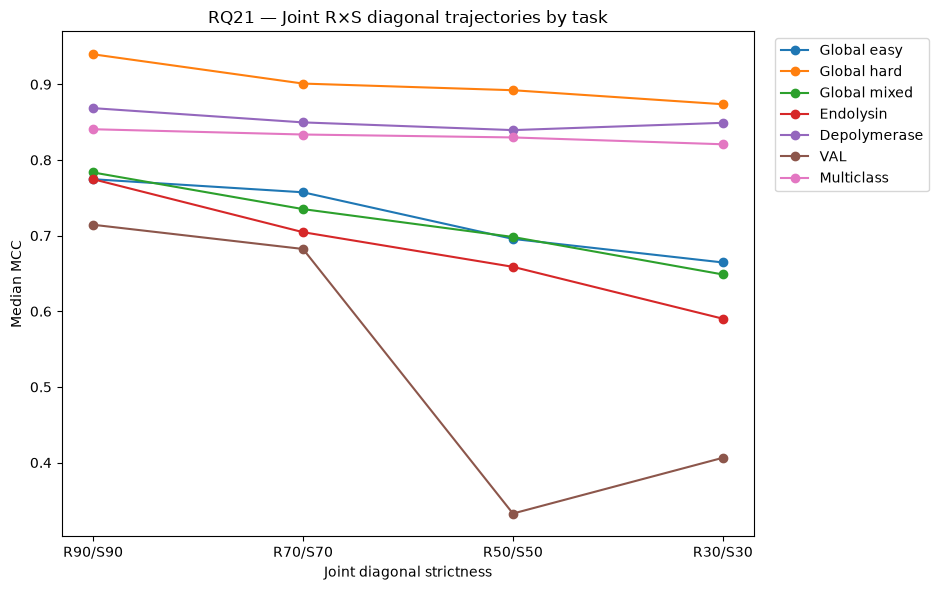

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq21_joint_RxS_trajectories/figures/rq21_joint_diagonal_by_task.png


In [12]:

# Figure 1 — joint diagonal by task.
fig, ax = plt.subplots(figsize=(9.5, 6.0))

for task in TASK_ORDER:
    sub = diag_task[diag_task["task"].eq(task)].sort_values("diagonal_order")
    if len(sub) == 0:
        continue
    ax.plot(
        sub["diagonal_order"],
        sub["median_mcc"],
        marker="o",
        label=TASK_LABEL.get(task, task),
    )

ax.set_xticks(
    [0, 1, 2, 3],
    ["R90/S90", "R70/S70", "R50/S50", "R30/S30"],
)
ax.set_xlabel("Joint diagonal strictness")
ax.set_ylabel("Median MCC")
ax.set_title("RQ21 — Joint R×S diagonal trajectories by task")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

path = FIG_DIR / "rq21_joint_diagonal_by_task.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


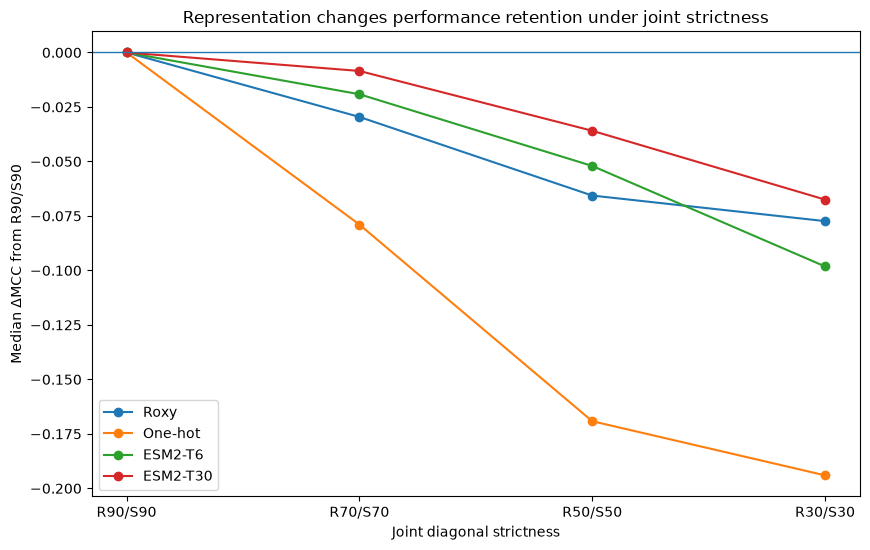

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq21_joint_RxS_trajectories/figures/rq21_joint_retention_by_representation.png


In [13]:

# Figure 2 — baseline-relative diagonal retention by representation.
fig, ax = plt.subplots(figsize=(8.8, 5.6))

for rep in REP_ORDER:
    sub = diag_rep[diag_rep["representation"].eq(rep)].sort_values("diagonal_order")
    if len(sub) == 0:
        continue
    ax.plot(
        sub["diagonal_order"],
        sub["median_delta"],
        marker="o",
        label=REP_LABEL.get(rep, rep),
    )

ax.axhline(0, linewidth=1)
ax.set_xticks(
    [0, 1, 2, 3],
    ["R90/S90", "R70/S70", "R50/S50", "R30/S30"],
)
ax.set_xlabel("Joint diagonal strictness")
ax.set_ylabel("Median ΔMCC from R90/S90")
ax.set_title("Representation changes performance retention under joint strictness")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq21_joint_retention_by_representation.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


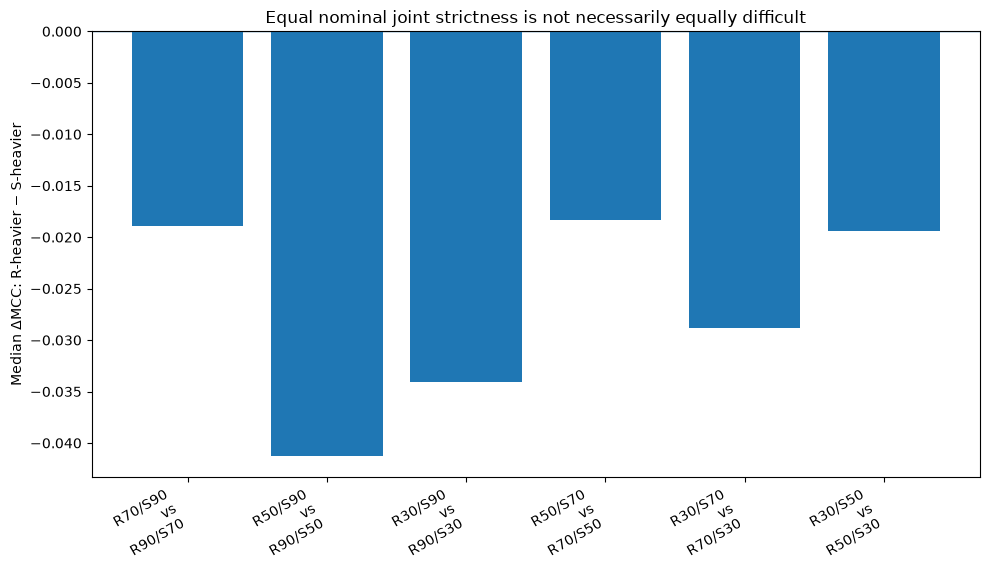

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq21_joint_RxS_trajectories/figures/rq21_asymmetric_allocation_contrasts.png


In [14]:

# Figure 3 — asymmetric allocation contrasts.
plot_asym = asym_pair_summary.copy()
plot_asym["contrast"] = (
    plot_asym["R_heavy_cell"] + "\nvs\n" + plot_asym["S_heavy_cell"]
)

fig, ax = plt.subplots(figsize=(10.0, 5.8))
x = np.arange(len(plot_asym))
ax.bar(x, plot_asym["median_delta"])
ax.axhline(0, linewidth=1)
ax.set_xticks(x, plot_asym["contrast"], rotation=30, ha="right")
ax.set_ylabel("Median ΔMCC: R-heavier − S-heavier")
ax.set_title("Equal nominal joint strictness is not necessarily equally difficult")
fig.tight_layout()

path = FIG_DIR / "rq21_asymmetric_allocation_contrasts.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


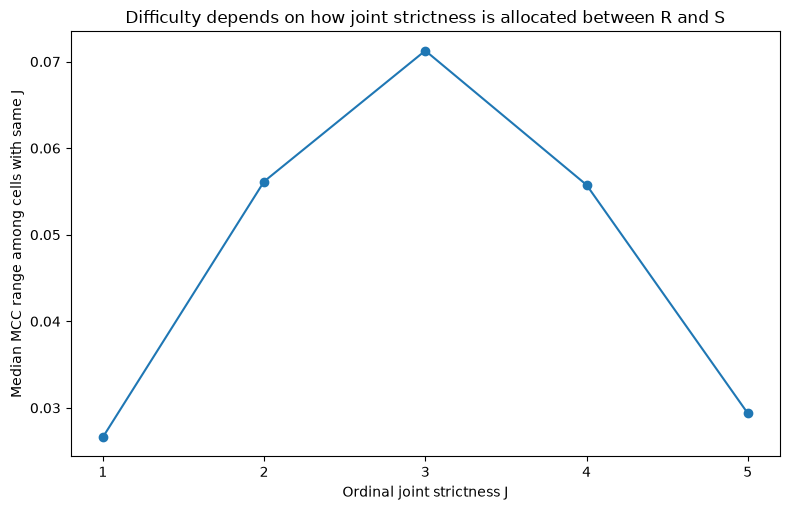

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq21_joint_RxS_trajectories/figures/rq21_within_joint_strictness_spread.png


In [15]:

# Figure 4 — within-J spread.
plot_J = joint_level_summary[
    joint_level_summary["joint_strictness"].between(1, 5)
].copy()

fig, ax = plt.subplots(figsize=(8.0, 5.2))
ax.plot(
    plot_J["joint_strictness"],
    plot_J["median_within_J_range"],
    marker="o",
)
ax.set_xticks(plot_J["joint_strictness"])
ax.set_xlabel("Ordinal joint strictness J")
ax.set_ylabel("Median MCC range among cells with same J")
ax.set_title("Difficulty depends on how joint strictness is allocated between R and S")
fig.tight_layout()

path = FIG_DIR / "rq21_within_joint_strictness_spread.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


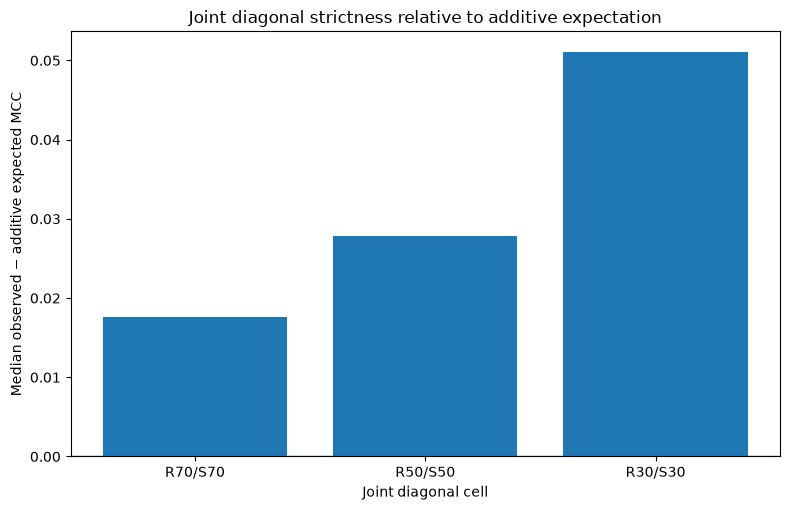

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq21_joint_RxS_trajectories/figures/rq21_joint_excess_over_additive.png


In [16]:

# Figure 5 — observed diagonal versus additive expectation.
plot_excess = joint_excess_summary[
    joint_excess_summary["joint_strictness"].gt(0)
].copy()

fig, ax = plt.subplots(figsize=(8.0, 5.2))
ax.bar(
    plot_excess["diagonal_cell"],
    plot_excess["median_excess"],
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Joint diagonal cell")
ax.set_ylabel("Median observed − additive expected MCC")
ax.set_title("Joint diagonal strictness relative to additive expectation")
fig.tight_layout()

path = FIG_DIR / "rq21_joint_excess_over_additive.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)



## 12. Interpretation guardrails

RQ21 should answer four distinct questions after real-data execution:

1. **How much performance is retained along the joint diagonal?**
2. **Is the joint trajectory smooth or are particular diagonal steps disproportionately damaging?**
3. **Does equal ordinal joint strictness imply equal difficulty?**
4. **When the same nominal strictness is allocated differently, is R-heavy strictness systematically more damaging than S-heavy strictness?**

The expected qualitative interpretation from earlier RQ2–RQ5 is that R-heavy allocations may often be more damaging, but RQ21 must report the observed contrasts directly.

### What RQ21 does not claim

- The diagonal cannot identify isolated causal R or S effects.
- The ordinal joint strictness index is not a calibrated biological distance.
- Native-test contrasts remain affected by test composition; common-test sensitivity is RQ18.
- The additive-excess diagnostic does not replace the full factorial RQ4 interaction analysis.
- Data quantity / cluster structure explanations belong to RQ22.
- Deployment selection belongs to RQ26.


## 13. Export canonical RQ21 artifacts

In [17]:

exports = {
    "rq21_joint_diagonal_cells.tsv": diag,
    "rq21_joint_diagonal_steps.tsv": joint_steps,
    "rq21_joint_step_summary.tsv": joint_step_summary,
    "rq21_diagonal_by_task.tsv": diag_task,
    "rq21_diagonal_by_representation.tsv": diag_rep,
    "rq21_diagonal_by_algorithm.tsv": diag_alg,
    "rq21_joint_level_spread.tsv": joint_level_spread,
    "rq21_joint_level_summary.tsv": joint_level_summary,
    "rq21_asymmetric_allocation_contrasts.tsv": asym,
    "rq21_asymmetric_pair_summary.tsv": asym_pair_summary,
    "rq21_asymmetry_by_task.tsv": asym_by_task,
    "rq21_asymmetry_by_representation.tsv": asym_by_rep,
    "rq21_joint_excess_over_additive.tsv": joint_excess,
    "rq21_joint_excess_summary.tsv": joint_excess_summary,
    "rq21_surface_mixed_trajectory_profiles.tsv": surface_profiles,
    "rq21_global_summary.tsv": global_summary,
}

for filename, df in exports.items():
    path = RQ21_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

manifest = {
    "rq": "RQ21",
    "question": "what happens when R and S become strict jointly?",
    "primary_metric": PRIMARY_METRIC,
    "input_source": "RQ6 canonical supervised surface cells",
    "joint_strictness_mapping": STRICTNESS_MAP,
    "diagonal": [f"R{r}/S{s}" for r, s in DIAGONAL],
    "asymmetry_tolerance_mcc": ASYM_TOL,
    "n_input_cells": int(len(surface_cells)),
    "n_surfaces": int(len(surface_profiles)),
    "n_diagonal_cells": int(len(diag)),
    "n_joint_steps": int(len(joint_steps)),
    "n_asymmetric_contrasts": int(len(asym)),
    "training_performed": False,
    "prediction_regeneration_performed": False,
    "bootstrap_performed": False,
    "common_test_recalculation_performed": False,
    "pu_analysis_performed": False,
    "scope_note": "RQ21 follows the frozen supervised mixed-RxS trajectory contract. PU R/S geometry remains in RQ13/RQ20.",
}

with open(RQ21_OUT / "rq21_manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("Wrote rq21_manifest.json")


Wrote rq21_joint_diagonal_cells.tsv: 560 rows
Wrote rq21_joint_diagonal_steps.tsv: 420 rows
Wrote rq21_joint_step_summary.tsv: 3 rows
Wrote rq21_diagonal_by_task.tsv: 28 rows
Wrote rq21_diagonal_by_representation.tsv: 16 rows
Wrote rq21_diagonal_by_algorithm.tsv: 20 rows
Wrote rq21_joint_level_spread.tsv: 980 rows
Wrote rq21_joint_level_summary.tsv: 7 rows
Wrote rq21_asymmetric_allocation_contrasts.tsv: 840 rows
Wrote rq21_asymmetric_pair_summary.tsv: 6 rows
Wrote rq21_asymmetry_by_task.tsv: 7 rows
Wrote rq21_asymmetry_by_representation.tsv: 4 rows
Wrote rq21_joint_excess_over_additive.tsv: 560 rows
Wrote rq21_joint_excess_summary.tsv: 4 rows
Wrote rq21_surface_mixed_trajectory_profiles.tsv: 140 rows
Wrote rq21_global_summary.tsv: 1 rows
Wrote rq21_manifest.json


## 14. Execution gates

In [18]:

required_exports = [
    "rq21_joint_diagonal_cells.tsv",
    "rq21_joint_diagonal_steps.tsv",
    "rq21_joint_step_summary.tsv",
    "rq21_diagonal_by_task.tsv",
    "rq21_diagonal_by_representation.tsv",
    "rq21_diagonal_by_algorithm.tsv",
    "rq21_joint_level_spread.tsv",
    "rq21_joint_level_summary.tsv",
    "rq21_asymmetric_allocation_contrasts.tsv",
    "rq21_asymmetric_pair_summary.tsv",
    "rq21_asymmetry_by_task.tsv",
    "rq21_asymmetry_by_representation.tsv",
    "rq21_joint_excess_over_additive.tsv",
    "rq21_joint_excess_summary.tsv",
    "rq21_surface_mixed_trajectory_profiles.tsv",
    "rq21_global_summary.tsv",
    "rq21_manifest.json",
]

assert len(surface_cells) == 2240
assert surface_cells.groupby(group_cols).size().eq(16).all()
assert len(surface_profiles) == 140

assert len(diag) == 560
assert diag.groupby(group_cols).size().eq(4).all()
assert len(joint_steps) == 420
assert len(asym) == 840
assert len(asym_pair_summary) == 6
assert len(joint_excess) == 560

for j, n in expected_n.items():
    assert joint_level_spread.loc[
        joint_level_spread["joint_strictness"].eq(j), "n_cells"
    ].eq(n).all()

assert diag.loc[
    diag["diagonal_cell"].eq("R90/S90"),
    "joint_delta_from_baseline",
].abs().max() < 1e-12

assert joint_excess.loc[
    joint_excess["diagonal_cell"].eq("R90/S90"),
    "joint_excess_over_additive",
].abs().max() < 1e-12

assert all((RQ21_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 5

print("RQ21_EXECUTION_GATES_OK")
print("Input RQ6 cells:", len(surface_cells))
print("Complete surfaces:", len(surface_profiles))
print("Diagonal cells:", len(diag))
print("Joint diagonal steps:", len(joint_steps))
print("Asymmetric allocation contrasts:", len(asym))
print("Canonical swapped pair types:", len(asym_pair_summary))
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print()
print(
    "Interpretation status: execution gates passed. "
    "Assign REAL-DATA PASS only after the executed notebook and outputs are inspected."
)


RQ21_EXECUTION_GATES_OK
Input RQ6 cells: 2240
Complete surfaces: 140
Diagonal cells: 560
Joint diagonal steps: 420
Asymmetric allocation contrasts: 840
Canonical swapped pair types: 6
Exports: 17
Figures: ['rq21_asymmetric_allocation_contrasts.png', 'rq21_joint_diagonal_by_task.png', 'rq21_joint_excess_over_additive.png', 'rq21_joint_retention_by_representation.png', 'rq21_within_joint_strictness_spread.png']

Interpretation status: execution gates passed. Assign REAL-DATA PASS only after the executed notebook and outputs are inspected.
